# 03: Testing the bridge with a real calculation, and bounding the screening from both sides

Notebook 02 ended with its most consequential and shakiest claim: *if the anomalous metal screening (~300 eV) acted on deuterons at rest, it would be like an electron ~10× heavier, which is enough for ~1 W/cm³.* It rested on a two-point interpolation. This notebook replaces that with a calculation and confronts it with data.

1. **Build a solver** for the d–d pair's quantum ground state in any potential, and get the fusion rate from the wavefunction at contact: $\Gamma = A\,|\psi(0)|^2$.
2. **Validate it** against the D₂ binding energy, the zero-point energy and Koonin–Nauenberg's $3\times10^{-64}$ s⁻¹, including convergence and the uncertainty in the potential curve.
3. **Heavy-electron scan**: the exact form of the bridge, with no interpolation.
4. **Lattice pair**: deuterons where they really are in PdD (2.75 Å apart), not in a D₂ molecule.
5. **Two-sided bound**: beam experiments fix how strong the extra screening is near contact. Neutron searches on loaded Pd/Ti at rest cap the rate. Together they bound how far the screening can extend.

Solver code: `cfsolve.py` (same folder). Numba is used if installed; otherwise it runs in pure Python, more slowly.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import optimize
from cfsolve import *
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"

# rate thresholds (fusions per pair per second)
LOG_WATT  = np.log10(5.6e-11)   # 1 W/cm^3 in PdD (notebook 01)
LOG_JONES = np.log10(1e-23)     # Jones et al. 1989 claimed rate (Ti)
LOG_LIMIT = np.log10(2e-26)     # PRL 65, 1196 (1990): upper limit, Pd and Ti, at rest
print(f"thresholds: 1 W/cm^3 -> 10^{LOG_WATT:.2f},  Jones -> 10^{LOG_JONES:.0f},  null limit -> 10^{LOG_LIMIT:.2f}")
print(f"reaction constant A = {A_cm3s():.3e} cm^3/s  (S(0) = {S_KEVB:.1f} keV b, both branches)")

thresholds: 1 W/cm^3 -> 10^-10.25,  Jones -> 10^-23,  null limit -> 10^-25.70
reaction constant A = 1.524e-16 cm^3/s  (S(0) = 109.3 keV b, both branches)


## 1. Method

For a bound pair, the fusion rate is the probability density of finding the two deuterons at contact, times a nuclear constant:

$$\Gamma = A\,|\psi(0)|^2,\qquad A = \frac{S(0)\,c}{\pi\alpha\,\mu c^2}\approx 1.5\times10^{-16}\ {\rm cm^3/s}$$

$A$ is $\langle\sigma v\rangle$ with the Coulomb tunneling factor removed (that factor is now inside $\psi$). $\psi$ is the s-wave ground state of the relative motion, $u'' = 2\mu\,(V(R)-E)\,u$, solved on a logarithmic grid from 0.5 fm to the outer classically forbidden region. Near the origin $u \approx R\,(1+R/2a)$, the regular solution for a repulsive Coulomb potential. The energy is found by node-counting bisection, and all amplitudes are tracked in log space because $\psi(0)$ is ~10⁻³⁷ of its peak.

**D₂ potential.** Born–Oppenheimer curve for H₂ (the same for D₂). Points for $R \ge 0.4$ bohr are Kolos–Wolniewicz values **recalled, not re-fetched** (the minimum matches the modern −1.1744759 hartree), splined to the He united-atom limit at $R=0$. Section 2 tests how much that matters.

## 2. Validation

In [2]:
D2 = solve(V_molecule(), 8.0, Rmin_well=0.5)
E0 = D2["E"]
print(f"binding D0       = {(-1-E0)*HARTREE_EV:.4f} eV     (experiment, D2: 4.556 eV)")
print(f"zero-point energy = {(E0+1.1744759)*219474.63:.0f} cm^-1   (experiment, D2: ~1542 cm^-1)")
print(f"fusion rate       = 10^{D2['log10_rate']:.2f} = {10**D2['log10_rate']:.2e} /s")
print("   Koonin & Nauenberg 1989: 3e-64 /s;   2025 recalculation (arXiv:2501.08338): 5.7e-64 /s")
print("\nconvergence:")
for h in [1e-4, 5e-5, 2.5e-5]:
    for r0 in [3e-6, 1e-5, 3e-5]:
        print(f"   step {h:.1e}, start {r0*52917.7:5.2f} fm  ->  10^{solve(V_molecule(), 8.0, r0=r0, h=h, Rmin_well=0.5)['log10_rate']:.3f}")

binding D0       = 4.5556 eV     (experiment, D2: 4.556 eV)
zero-point energy = 1550 cm^-1   (experiment, D2: ~1542 cm^-1)
fusion rate       = 10^-63.60 = 2.51e-64 /s
   Koonin & Nauenberg 1989: 3e-64 /s;   2025 recalculation (arXiv:2501.08338): 5.7e-64 /s

convergence:


   step 1.0e-04, start  0.16 fm  ->  10^-63.601


   step 1.0e-04, start  0.53 fm  ->  10^-63.600
   step 1.0e-04, start  1.59 fm  ->  10^-63.599


   step 5.0e-05, start  0.16 fm  ->  10^-63.601


   step 5.0e-05, start  0.53 fm  ->  10^-63.600


   step 5.0e-05, start  1.59 fm  ->  10^-63.599


   step 2.5e-05, start  0.16 fm  ->  10^-63.601


   step 2.5e-05, start  0.53 fm  ->  10^-63.600


   step 2.5e-05, start  1.59 fm  ->  10^-63.599


In [3]:
print("sensitivity to the short-range potential (the part that was recalled, not fetched):")
rows = []
for label, kw in [("baseline", {}),
                  ("E_el(R<=0.6) +0.05 Ha", dict(shift_short=+0.05)),
                  ("E_el(R<=0.6) -0.05 Ha", dict(shift_short=-0.05)),
                  ("E_el(R<=0.6) +0.15 Ha", dict(shift_short=+0.15)),
                  ("E_el(R<=0.6) -0.15 Ha", dict(shift_short=-0.15)),
                  ("UA curvature x0.5", dict(c2_ua=0.5*1.77)),
                  ("UA curvature x4 (Bingel-like)", dict(c2_ua=7.58))]:
    lr = solve(V_molecule(1.0, make_Eel(**kw)), 8.0, Rmin_well=0.5)["log10_rate"]
    rows.append((label, lr)); print(f"   {label:32s} 10^{lr:.2f}")
spread = max(r[1] for r in rows) - min(r[1] for r in rows)
print(f"\nfull spread: {spread:.2f} decades")

sensitivity to the short-range potential (the part that was recalled, not fetched):


   baseline                         10^-63.60


   E_el(R<=0.6) +0.05 Ha            10^-64.30


   E_el(R<=0.6) -0.05 Ha            10^-62.87


   E_el(R<=0.6) +0.15 Ha            10^-65.60


   E_el(R<=0.6) -0.15 Ha            10^-61.29


   UA curvature x0.5                10^-63.43


   UA curvature x4 (Bingel-like)    10^-64.56

full spread: 4.31 decades


**Validation result:** the solver reproduces the D₂ binding energy to 0.0004 eV and the zero-point energy to <1%. The fusion rate comes out at **2.5×10⁻⁶⁴ s⁻¹**, between Koonin–Nauenberg (3×10⁻⁶⁴) and the 2025 recalculation (5.7×10⁻⁶⁴). It is converged in step size and starting radius to 0.002 decades.

**The rate is sensitive to the short-range potential:** a 0.05-hartree (1.4 eV) error below 0.3 Å shifts it by about 0.7 decades, and 0.15 hartree by about 2.3. Kolos–Wolniewicz values are accurate to ~10⁻⁵ hartree, so the real risk is my recall of them. The independent checks (binding energy, zero-point energy, and agreement with Koonin–Nauenberg to 0.08 decades) suggest the recalled curve is right to well under 0.05 hartree. **Working uncertainty: about ±1 decade.** That's small against gaps of tens of orders, but it should be kept in mind.

## 3. Heavy-electron scan: the bridge without interpolation

m* for 1 W/cm^3 : 9.19   (notebook 02 estimate: 10.2)  -> molecular screening ~230 eV
m* for Jones    : 4.20
m* at null limit: 3.68

muon (m* = 206.8), Born-Oppenheimer S-wave: 10^11.6 /s  (BO is poor at muon mass; real dd-mu fusion is from J=1 states, ~1e8-1e9 /s. Order-of-magnitude only)


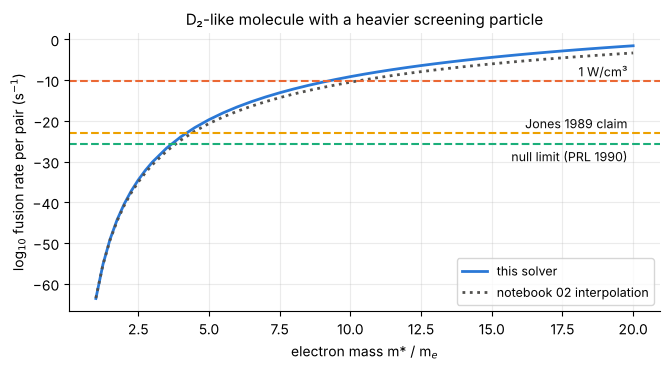

In [4]:
ms = np.concatenate([np.linspace(1, 3, 9), np.linspace(3.5, 20, 34)])
lr_m = np.array([solve(V_molecule(m), 8.0/m, Rmin_well=0.5/m)["log10_rate"] for m in ms])
interp02 = lambda m: 14.0 - 77.5/np.sqrt(m)          # notebook 02's two-anchor fit
def m_for(target):
    return optimize.brentq(lambda m: np.interp(m, ms, lr_m) - target, ms[0], ms[-1])
m_w, m_j, m_l = m_for(LOG_WATT), m_for(LOG_JONES), m_for(LOG_LIMIT)
print(f"m* for 1 W/cm^3 : {m_w:.2f}   (notebook 02 estimate: 10.2)  -> molecular screening ~{25*m_w:.0f} eV")
print(f"m* for Jones    : {m_j:.2f}")
print(f"m* at null limit: {m_l:.2f}")
print(f"\nmuon (m* = 206.8), Born-Oppenheimer S-wave: 10^{solve(V_molecule(206.77), 8/206.77, Rmin_well=0.5/206.77)['log10_rate']:.1f} /s"
      "  (BO is poor at muon mass; real dd-mu fusion is from J=1 states, ~1e8-1e9 /s. Order-of-magnitude only)")

fig, ax = plt.subplots(figsize=(6.8,3.8))
ax.plot(ms, lr_m, color=BLUE, lw=2, label="this solver")
ax.plot(ms, interp02(ms), color=MUTED, lw=2, ls=":", label="notebook 02 interpolation")
for y, lab, col, dy in [(LOG_WATT,"1 W/cm³",ORANGE,1.2),(LOG_JONES,"Jones 1989 claim",YELLOW,1.2),(LOG_LIMIT,"null limit (PRL 1990)",AQUA,-4.2)]:
    ax.axhline(y, color=col, ls="--", lw=1.5); ax.text(19.8, y+dy, lab, ha="right", fontsize=9, color=INK)
ax.set_xlabel("electron mass m* / m$_e$"); ax.set_ylabel("log$_{10}$ fusion rate per pair (s$^{-1}$)")
ax.set_title("D₂-like molecule with a heavier screening particle"); ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig("../figures/03_heavy_electron.png", dpi=130); plt.show()

**Result:** the full calculation needs a **slightly lighter** heavy electron than the interpolation: about **9×** rather than 10×, equivalent to ~230 eV of molecular screening. Notebook 02's bridge survives the real calculation; if anything, it was conservative. *But this is for a D₂ molecule, where the heavy electron also shrinks the molecule.* That's the part section 4 tests.

## 4. The lattice pair: deuterons where they actually are

In PdD each deuteron sits in its own octahedral site, 2.75 Å from its nearest neighbour. Model of the pair's relative motion:
* repulsion screened by the metal's electrons over the **Thomas–Fermi length** (0.57 Å, notebook 02 §4),
* an isotropic harmonic restoring force from the lattice (PdD optical phonon, 37 meV).

It's crude (isotropic, s-wave, independent sites), but it puts the pair at the right distance with the right stiffness.

In [5]:
L0 = solve(V_lattice(), 12.0, Rmin_well=1.0)
print(f"lattice pair, baseline:   10^{L0['log10_rate']:.1f} /s     (D2 molecule: 10^{D2['log10_rate']:.1f})")
print("\nsensitivity:")
for lab, kw in [("spacing 2.50 A", dict(d0_A=2.50)), ("spacing 2.00 A (compressed)", dict(d0_A=2.0)),
                ("spacing 1.50 A (vacancy-like)", dict(d0_A=1.5)),
                ("phonon 60 meV (stiffer)", dict(phonon_meV=60)), ("phonon 20 meV (softer)", dict(phonon_meV=20)),
                ("TF length 1.0 A (weaker screening)", dict(lam_TF_A=1.0)), ("TF length 0.3 A (stronger)", dict(lam_TF_A=0.3))]:
    print(f"   {lab:36s} 10^{solve(V_lattice(**kw), 12.0, Rmin_well=0.5)['log10_rate']:.1f}")

lattice pair, baseline:   10^-123.9 /s     (D2 molecule: 10^-63.6)

sensitivity:


   spacing 2.50 A                       10^-121.1


   spacing 2.00 A (compressed)          10^-116.4


   spacing 1.50 A (vacancy-like)        10^-112.7


   phonon 60 meV (stiffer)              10^-131.0


   phonon 20 meV (softer)               10^-121.3


   TF length 1.0 A (weaker screening)   10^-151.4


   TF length 0.3 A (stronger)           10^-96.0


**Result:** a lattice pair fuses at about **10⁻¹²⁴ s⁻¹**, roughly 60 orders of magnitude below a D₂ molecule. Squeezing it to vacancy-like 1.5 Å spacing recovers part of that, not all. **Any static mechanism has to bring the pair much closer than the lattice holds it.** That's what the heavy electron does "for free" inside a molecule, and what screening alone doesn't.

## 5. Extra screening: what the beam data allow, and what the neutron limits forbid

Add extra screening near the pair: $\Delta V(R) = -\Delta U\,e^{-R/\ell}$, with strength $\Delta U$ at contact and range $\ell$.

* **Beam constraint.** Beams measure the potential shift at their classical turning point, $R_{tp}\approx 0.004$ Å (2.5–5 keV c.m.). Seeing $U_{\rm meas}$ there needs $\Delta U = U_{\rm meas}\,e^{R_{tp}/\ell}$. Excess over gas: $U_{\rm meas}\approx165$–$575$ eV. This is the **beam-consistent band**.
* **Static constraint.** Loaded Pd and Ti at rest: rate < 2×10⁻²⁶ s⁻¹ per pair (*PRL* 65, 1196, 1990), applied to the **lattice** pair.

**A complication the scan turned up:** past a certain range, the extra attraction creates a **new bound d–d state** at short separation, below the lattice state. Then there are two rates:
* **Fusion inside the bound state** (solver, global ground state), and
* **Tunneling into it** from the lattice site (WKB through the barrier between the two wells, with attempt frequency set by the phonon).

The effective rate per lattice pair is roughly the slower of the two (a pair has to get in, then fuse).

In [6]:
E_lat = L0["E"]; NU = 37e-3/4.135667e-15           # lattice-state energy, phonon attempt frequency (Hz)
def evaluate(dU, ell, Vb=V_lattice(), Rmax=12.0, Rmin=1.0, d0_bohr=2.75/BOHR_A):
    ex = extra_screening(dU, ell); V = lambda R: Vb(R) + ex(R)
    try:
        lr = solve(V, Rmax, Rmin_well=Rmin)["log10_rate"]
        return dict(kind="lattice", eff=lr, fuse=lr, leak=np.inf, Eb=np.nan, rb=np.nan)
    except Collapse:
        B = solve(V, Rmax, Rmin_well=1e-4)
        r = np.logspace(-4, np.log10(Rmax), 200000); v = V(r)
        imin = np.argmin(np.where(r < Rmin, v, np.inf))
        sel = (r > r[imin]) & (r < d0_bohr) & (v > E_lat)
        G = 2*np.trapezoid(np.sqrt(2*MU_DD*np.clip(v[sel] - E_lat, 0, None)), r[sel])
        leak = np.log10(NU) - G/np.log(10)
        rb = float(np.trapezoid(B["r"]*B["u"]**2, B["r"]))*BOHR_A
        return dict(kind="bound", eff=min(leak, B["log10_rate"]), fuse=B["log10_rate"], leak=leak,
                    Eb=B["E"]*HARTREE_EV, rb=rb)

R_TP = 0.004
beam = lambda U, ell: U*np.exp(R_TP/ell)
ells_b = np.logspace(np.log10(0.01), np.log10(0.4), 45)
band = {U: [evaluate(beam(U, l), l) for l in ells_b] for U in [165, 300, 575]}
for U, rows in band.items():
    eff = np.array([r["eff"] for r in rows]); kinds = [r["kind"] for r in rows]
    k_b = kinds.index("bound") if "bound" in kinds else None
    over = np.where(eff > LOG_LIMIT)[0]
    print(f"U_meas = {U} eV")
    print(f"   lattice-site rate at ell = 0.02 / 0.05 A : 10^{np.interp(0.02, ells_b, eff):.0f} / 10^{np.interp(0.05, ells_b, eff):.0f}")
    if k_b is not None:
        r = rows[k_b]
        print(f"   new bound d-d state appears at ell = {ells_b[k_b]:.3f} A: separation {r['rb']:.2f} A, binding {r['Eb']:.1f} eV, "
              f"fusion inside 10^{r['fuse']:.1f}/s, tunnelling in 10^{r['leak']:.1f}/s")
    print(f"   effective rate exceeds the null limit for ell >= {ells_b[over[0]]:.3f} A" if len(over) else "   never exceeds the null limit")
    print(f"   maximum effective rate on the band (ell <= 0.4 A): 10^{eff.max():.1f}  -> 1 W/cm^3 needs 10^{LOG_WATT:.1f}\n")

U_meas = 165 eV
   lattice-site rate at ell = 0.02 / 0.05 A : 10^-123 / 10^-119
   new bound d-d state appears at ell = 0.173 A: separation 0.24 A, binding -0.7 eV, fusion inside 10^-27.1/s, tunnelling in 10^-31.3/s
   never exceeds the null limit
   maximum effective rate on the band (ell <= 0.4 A): 10^-27.1  -> 1 W/cm^3 needs 10^-10.3

U_meas = 300 eV
   lattice-site rate at ell = 0.02 / 0.05 A : 10^-121 / 10^-114
   new bound d-d state appears at ell = 0.114 A: separation 0.13 A, binding -7.1 eV, fusion inside 10^-16.4/s, tunnelling in 10^-46.5/s
   effective rate exceeds the null limit for ell >= 0.159 A
   maximum effective rate on the band (ell <= 0.4 A): 10^-17.9  -> 1 W/cm^3 needs 10^-10.3

U_meas = 575 eV
   lattice-site rate at ell = 0.02 / 0.05 A : 10^-119 / 10^-103
   new bound d-d state appears at ell = 0.063 A: separation 0.07 A, binding -12.8 eV, fusion inside 10^-7.2/s, tunnelling in 10^-66.1/s
   effective rate exceeds the null limit for ell >= 0.135 A
   maximum effec

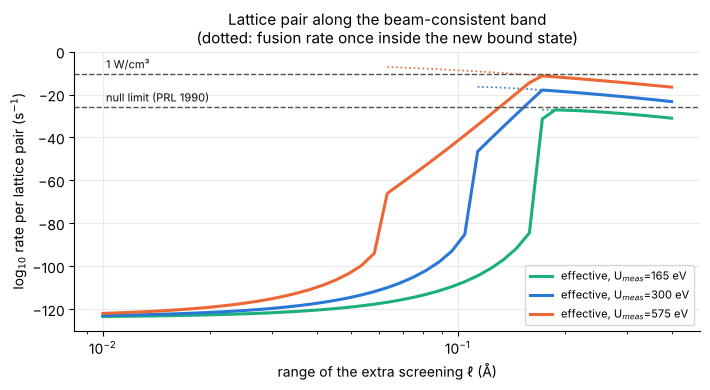

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
for U, col in [(165, AQUA), (300, BLUE), (575, ORANGE)]:
    rows = band[U]
    ax.plot(ells_b, [r["eff"] for r in rows], color=col, lw=2.2, label=f"effective, U$_{{meas}}$={U} eV")
    fz = [r["fuse"] if r["kind"]=="bound" else np.nan for r in rows]
    ax.plot(ells_b, fz, color=col, lw=1.2, ls=":")
for y, lab in [(LOG_WATT, "1 W/cm³"), (LOG_LIMIT, "null limit (PRL 1990)")]:
    ax.axhline(y, color=MUTED, ls="--", lw=1); ax.text(0.0102, y+2.5, lab, fontsize=8, color=INK)
ax.set_xscale("log"); ax.set_ylim(-130, 0)
ax.set_xlabel("range of the extra screening ℓ (Å)"); ax.set_ylabel("log$_{10}$ rate per lattice pair (s$^{-1}$)")
ax.set_title("Lattice pair along the beam-consistent band\n(dotted: fusion rate once inside the new bound state)")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.savefig("../figures/03_along_band.png", dpi=130); plt.show()

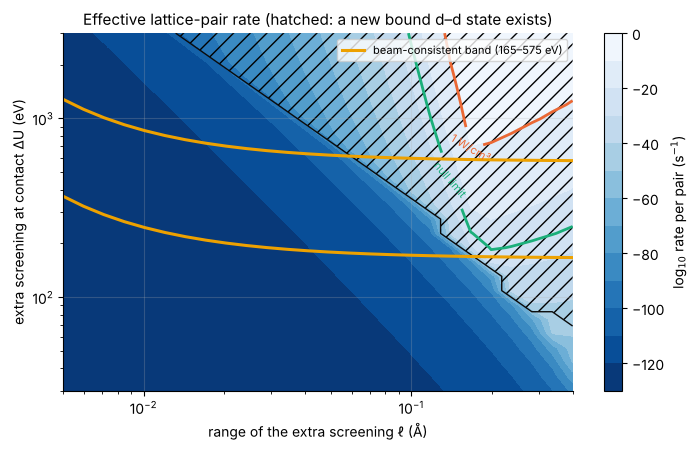

In [8]:
ells = np.logspace(np.log10(0.005), np.log10(0.4), 26); dUs = np.logspace(np.log10(30), np.log10(3000), 26)
Z = np.full((len(dUs), len(ells)), np.nan); Kb = np.zeros_like(Z, bool)
for i, dU in enumerate(dUs):
    for j, ell in enumerate(ells):
        r = evaluate(dU, ell); Z[i, j] = r["eff"]; Kb[i, j] = r["kind"] == "bound"
X, Y = np.meshgrid(ells, dUs)
fig, ax = plt.subplots(figsize=(7.2, 4.6))
cf = ax.contourf(X, Y, np.clip(Z, -130, 0), levels=np.arange(-130, 1, 10), cmap="Blues_r")
cs = ax.contour(X, Y, Z, levels=[LOG_LIMIT, LOG_WATT], colors=[AQUA, ORANGE], linewidths=2)
ax.clabel(cs, fmt={LOG_LIMIT: "null limit", LOG_WATT: "1 W/cm³"}, fontsize=8)
ax.contourf(X, Y, Kb.astype(float), levels=[0.5, 1.5], colors="none", hatches=["//"])
ax.contour(X, Y, Kb.astype(float), levels=[0.5], colors=[INK], linewidths=1)
for U in [165, 575]:
    ax.plot(ells, beam(U, ells), color=YELLOW, lw=2.2, label="beam-consistent band (165–575 eV)" if U == 165 else None)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(ells[0], ells[-1]); ax.set_ylim(dUs[0], dUs[-1])
ax.set_xlabel("range of the extra screening ℓ (Å)"); ax.set_ylabel("extra screening at contact ΔU (eV)")
ax.set_title("Effective lattice-pair rate (hatched: a new bound d–d state exists)")
ax.legend(loc="upper right", fontsize=8); fig.colorbar(cf, ax=ax, label="log$_{10}$ rate per pair (s$^{-1}$)")
plt.tight_layout(); plt.savefig("../figures/03_screening_map.png", dpi=130); plt.show()

## 6. What this establishes

1. **The bridge is real arithmetic.** In a molecule, an electron ~9× heavier gives watt-level rates; the full calculation agrees with notebook 02 to within a decade.
2. **The lattice is the bottleneck, not the screening strength.** A lattice pair starts ~60 orders below a D₂ molecule. If the measured extra screening reaches only a few hundredths of an Å, which is all the beam data show, the lattice rate stays below 10⁻¹⁰⁰ for every measured strength.
3. **There's a cliff, not a ramp.** As the screening's range grows, nothing much happens until the extra attraction **binds two deuterons into a new short-range state**. The stronger the screening, the closer that bound pair sits: about 0.24 Å for 165 eV, 0.13 Å for 300 eV and 0.07 Å for 575 eV. Its internal fusion rate runs from ~10⁻²⁷ to ~10⁻⁷ s⁻¹. Getting into it from a lattice site needs tunneling, which is extremely slow at first and speeds up as the range grows.
4. **The neutron limit becomes a measurement of the screening's range.** On the beam-consistent band:
   * **165 eV:** the effective rate never reaches the null limit in this model. It is unconstrained, and also useless for energy.
   * **300 eV:** it crosses the limit at ℓ ≈ 0.16 Å; **at rest the screening can't extend farther than that.**
   * **575 eV:** it crosses at ℓ ≈ 0.135 Å, and the highest rate on the band reaches ~10⁻¹¹ s⁻¹, about one decade short of watt level and within this model's uncertainty.

   **The robust conclusion:** wherever the beam-consistent screening approaches watt-level rates, it is *already above the neutron limit* by ~15 orders of magnitude. So a screening-only mechanism that produced watts in loaded Pd/Ti would have produced abundant neutrons, and the 1990 searches saw none.
5. **What's left for "something missing":** a mechanism that compresses deuteron pairs to ≲0.1 Å *and* sends the energy into a channel with **no neutrons** (heat only). The neutron limit then no longer applies, but the 10⁹ timescale problem from notebook 01 does. Separately, a d–d bound state with eV-scale binding should show up in PdD thermochemistry (a check not done here).

**Caveats:** the lattice model is isotropic, single-pair and harmonic. The screening profile is one shape (exponential). The bound-state treatment is equilibrium plus WKB with a phonon attempt frequency. The recalled potential points carry about ±1 decade. The null limit is one experiment, checked at abstract level. The obvious next robustness tests are a different profile shape (Yukawa, step) and an anisotropic lattice potential.

## 7. Source status

| Input | Value | Status |
|---|---|---|
| H₂ BO curve, R ≥ 0.4 bohr | Kolos & Wolniewicz 1965 | **Recalled**; minimum matches Pachucki 2010; sensitivity tested (§2) |
| He united-atom energy | −2.903724 Ha | Standard |
| S(0), both branches | 109.3 keV b | Bosch–Hale 1992 fit parameters (notebook 01) |
| Koonin–Nauenberg D₂ rate | 3×10⁻⁶⁴ s⁻¹ | Confirmed (*Nature* 339, 690) |
| 2025 recalculation | 5.7×10⁻⁶⁴ s⁻¹ | Confirmed (arXiv:2501.08338, abstract) |
| D₂ D₀, ZPE | 4.556 eV, ~1542 cm⁻¹ | Standard spectroscopic values |
| Null limit, Pd & Ti at rest | < 2×10⁻²⁶ s⁻¹ per pair | Confirmed (abstract), *PRL* 65, 1196 (1990) |
| Weaker limit | < 3.6×10⁻²³ s⁻¹ | Badurek et al. 1989 (abstract) |
| Jones claim | ~10⁻²³ s⁻¹ (Ti) | Confirmed via secondary sources |
| PdD optical phonon | ~37 meV | Notebook 01 |
| Thomas–Fermi length, Pd | 0.57 Å | Computed, notebook 02 |
| dd-μ fusion rate | ~10⁸–10⁹ s⁻¹ (J=1) | Secondary/abstract; used only as a sanity note |